In [29]:
import numpy as np

#function to calculate the mass of the hole that is cut out
def calculate_mass_hole(mass_old:float, radius_cilinder:float, radius_hole:float):

    '''
    mass old is the mass of the cilinder without a hole [kg]
    radius cilinder is the radius of the complete cilinder [m]
    radius hole is the radius of the hole we made in the cilinder [m]
    '''

    #calculating the mass of the taken out hole
    mass_hole = (radius_hole/radius_cilinder) ** 2 * mass_old
    return mass_hole

#funtion to calculate the moment of inertia of the cilinder with a hole
def calucate_moment_of_inertia(mass_old:float, radius_cilinder:float, radius_hole:float, offset_1:float, offset_2:float):

    '''
    mass old is the mass of the cilinder without a hole [kg]
    radius cilinder is the radius of the complete cilinder [m]
    radius hole is the radius of the hole we made in the cilinder [m]
    offset 1 is the distance between the center of mass and the rotation axis [m]
    offset 2 is the distance between the center of the cut out hole and the rotation axis [m]
    '''

    #calculating the mass of the new cilinder with hole and mass of the hole
    mass_hole = calculate_mass_hole(mass_old, radius_cilinder, radius_hole)
    mass_new = mass_old - mass_hole

    #calculating the moment of inertia of the old cilinder and the hole of the cilinder
    moment_of_inertia_old_cilinder = 0.5 * mass_old * (radius_cilinder) ** 2
    moment_of_inertia_hole = 0.5 * mass_hole * (radius_hole) ** 2 + mass_hole * (offset_2) ** 2

    #calculating the moment of inertia of the new cilinder looking at it from the center of mass
    moment_of_inertia_cm = moment_of_inertia_old_cilinder - moment_of_inertia_hole

    #calculating the moment of inertia of the new cilinder looking at it form the ratation axis
    moment_of_inertia = moment_of_inertia_cm + mass_new * (offset_1) ** 2
    return moment_of_inertia

#calculating the acceleration and angular acceleration
def calculating_acceleration_and_alpha(moment_of_inertia:float, g:float, mass:float, radius:float, angle_gravity_force:float, angle_slope:float):

    '''
    moment of inertia is the moment of inertia of the cilinder with a hole [kg m^2]
    g is de gravitational velocity [m/s^2]
    mass is the mass of the cilinder with hole [kg]
    radius is the radius of the cilinder [m]
    angle_gravity_force is the angle of the center of mass of the cilinder with hole if you take the slope as the x-as [rad]
    angle_slope is the ange of the slope [rad]
    '''

    #calculating the acceleration
    acceleration = ((radius) ** 2 * mass * g * (np.sin(angle_slope) + np.cos(angle_gravity_force))) / (((radius) ** 2) * mass + moment_of_inertia)

    # calculating the angular acceleration
    alpha = -acceleration / radius
    return acceleration, alpha 

#calculating the distance between the center of mass and the rotation axis
def calculating_offset_1(distance_cilinder_cm_hole_cm:float, mass_old:float, radius_cilinder:float, radius_hole:float):
    
    '''
    distance_cilinder_cm_hole_cm is the distance between the old center of mass, before the hole was taken out, and the center of the taken out hole [m]
    mass old is the mass of the cilinder without a hole [kg]
    radius cilinder is the radius of the complete cilinder [m]
    radius hole is the radius of the hole we made in the cilinder [m]    
    '''

    #calling the calculate_mass_function
    mass_hole = calculate_mass_hole(mass_old, radius_cilinder, radius_hole)

    #calculating the distance between the center of mass and the rotation axis
    offset_1 = abs((-mass_hole*distance_cilinder_cm_hole_cm) / (mass_hole))
    return offset_1


#constants
GRAVITATION_VELOCITY = 9.81         #[m/s^2]
L = 10.0                            #[m]
MASS = 4.0                          #[kg]
RADIUS_CILINDER = 0.25              #[m]
RADIUS_HOLE = 0.025                 #[m]
OFFSET_2 = 0.125                    #[m]
OFFSET_1 = calculating_offset_1(OFFSET_2, MASS, RADIUS_CILINDER, RADIUS_HOLE) #[m]

#np array can have as many angles as you want
ANGLE_SLOPE = np.array([np.deg2rad(40)])
I = calucate_moment_of_inertia(MASS, RADIUS_CILINDER, RADIUS_HOLE, OFFSET_1, OFFSET_2)    #[kg m^2]

#variables
t0 = 0          #initial time [s]
v0 = 0          #initial velocity [m/s]
x0 = 0          #initial position [m]
phi0 = 0.0      #initial angle [rad]
omega0 = 0      #initial angular velocity = [rad/s]
dt = 0.0001      #time increments [s]

#creating dictionaries
time_dic = {}
position_dic = {}
velocity_dic = {}
acceleration_dic = {}
angle_dic = {}
angular_velocity_dic = {}
angular_acceleration_dic = {}

#giving initial values to there variables
x, phi, v, omega, t = x0, phi0, v0, omega0, t0
a, alpha = calculating_acceleration_and_alpha(I, GRAVITATION_VELOCITY, MASS, RADIUS_CILINDER, phi, ANGLE_SLOPE[0])

#creating lists to add values of the variables to later
position = [x0]
velocity = [v0]
angle = [phi0]
angular_velocity = [omega0]
time = [t0]
acceleration = [a]
angular_acceleration = [alpha]
end_times = []

#for loop so that every slope angle has an calculation. f is to keep track of the how many times de loop has gone.
for theta, f in zip(ANGLE_SLOPE, range(len(ANGLE_SLOPE))):

    #reastablising the variables as there begin values for ANGLE_SLOPE 2, 3 ect. 
    x, phi, v, omega, t = x0, phi0, v0, omega0, t0

    # while loop in which the simulation takes place
    while True:
    
        #updating the variables every loop
        x = x + v * dt
        phi = (phi + omega * dt) % (2 * np.pi)
        v = v + a * dt
        omega = omega + alpha * dt
        a, alpha = calculating_acceleration_and_alpha(I, GRAVITATION_VELOCITY, MASS, RADIUS_CILINDER, phi, theta)
        t = t + dt

        #adding the variables to their lists
        position.append(x)
        velocity.append(v)
        angle.append(phi)
        angular_velocity.append(omega)
        time.append(t)
        acceleration.append(a)
        angular_acceleration.append(alpha)
        
        #condition to end the while loop. It's when the ball has gone further than the length of the planck
        if x >= L:

            #adding every list to a dictionary under a diffrent name
            time_dic['time_{0}'.format(f)] = time
            velocity_dic['velocity_{0}'.format(f)] = velocity
            position_dic['position_{0}'.format(f)] = position
            acceleration_dic['acceleration_{0}'.format(f)] = acceleration
            angle_dic['angle_{0}'.format(f)] = angle
            angular_velocity_dic['angular_velocity_{0}'.format(f)] = angular_velocity
            angular_acceleration_dic['angular_acceleration_{0}'.format(f)] = angular_acceleration
            end_times.append(time[-1])

            #to delete the old list so that is doesn't contain the values of the first simulation anymore
            if f != len(ANGLE_SLOPE) - 1:
                a, alpha = calculating_acceleration_and_alpha(I, GRAVITATION_VELOCITY, MASS, RADIUS_CILINDER, phi, ANGLE_SLOPE[f + 1])

                position = [x0]
                velocity = [v0]
                angle = [phi0]
                angular_velocity = [omega0]
                time = [t0]
                acceleration = [a]
                angular_acceleration = [alpha]
            
            break

<>:78: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:78: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\qwpie\AppData\Local\Temp\ipykernel_32492\16921187.py:78: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax[0, 1].yaxis.set_major_formatter(tck.FormatStrFormatter('%g $\pi$'))


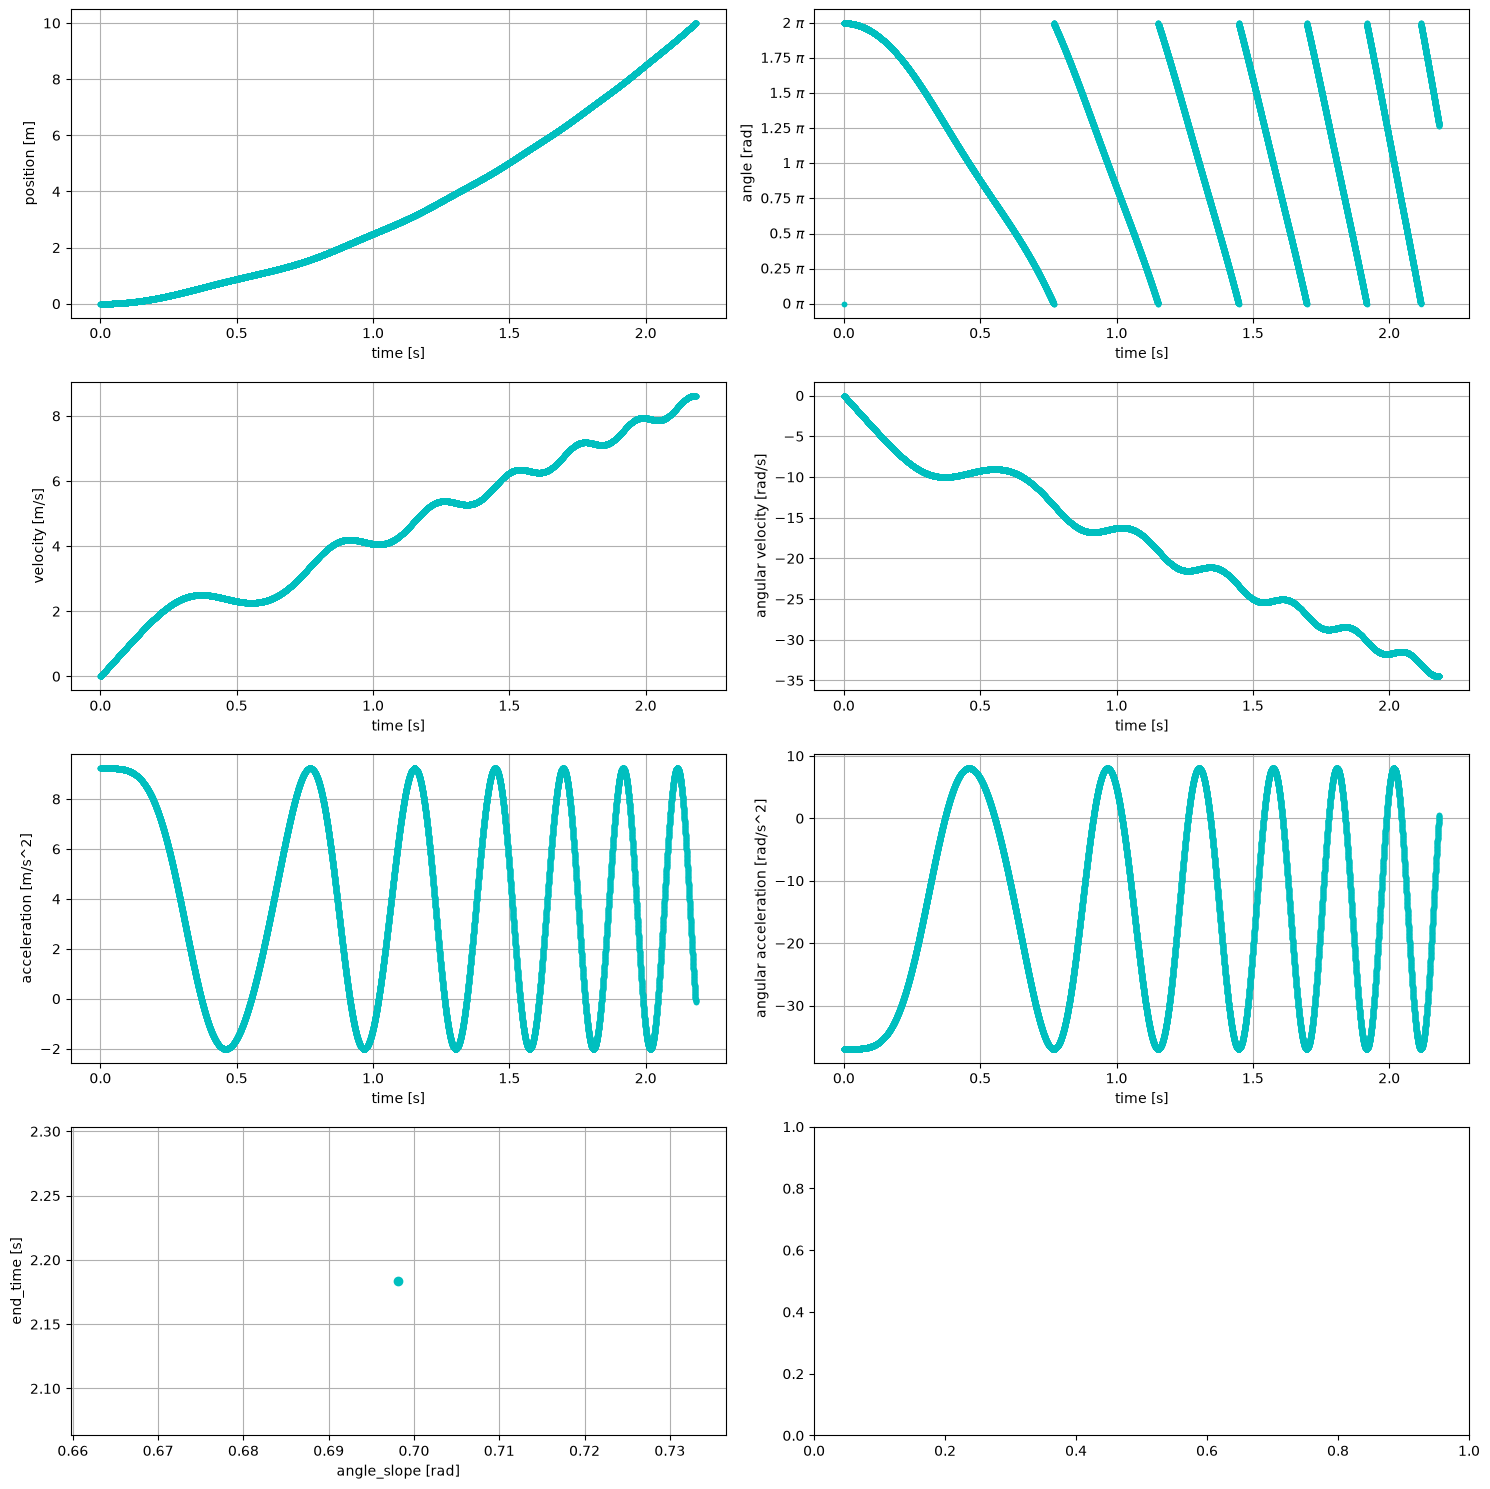

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as tck

#creating a enviorment for the plots
fig, ax = plt.subplots(4, 2, figsize = (15, 15))




#for loop to plot all the simulations
for p_value, v_value, ac_value, an_value, an_v_value, an_ac_value, t_value, i in zip(position_dic.values(), velocity_dic.values(), acceleration_dic.values(), angle_dic.values(), angular_velocity_dic.values(), angular_acceleration_dic.values(), time_dic.values(), range(len(ANGLE_SLOPE))):

    an_value_new = []
    
    #to get the simulations for the diffrent angles a diffrent color.
    if i%6 == 0:
        color_dot = 'c.' 
    elif i%6 == 1:
        color_dot = 'm.'
    elif i%6 == 2:
        color_dot = 'g.'
    elif i%6 == 3:
         color_dot = 'y.'
    elif i%6 == 4:
        color_dot = 'k.'
    else:
        color_dot = 'b.'

    for an in an_value:
        an_value_new.append(an / np.pi)

    #plotting all the simulations
    ax[0, 0].plot(t_value, p_value, color_dot)
    ax[1, 0].plot(t_value, v_value, color_dot)
    ax[2, 0].plot(t_value, ac_value, color_dot)
    ax[0, 1].plot(t_value, an_value_new, color_dot)
    ax[1, 1].plot(t_value, an_v_value, color_dot)
    ax[2, 1].plot(t_value, an_ac_value, color_dot)

#plotting end time against angle slope
ax[3,0].plot(ANGLE_SLOPE, end_times, 'co')

#setting x/y labels to the plots
ax[0, 0].set(
    xlabel= 'time [s]',
    ylabel = 'position [m]'
)

ax[1, 0].set(
    xlabel= 'time [s]',
    ylabel = 'velocity [m/s]'
)

ax[2, 0].set(
    xlabel= 'time [s]',
    ylabel = 'acceleration [m/s^2]'
)

ax[0, 1].set(
    xlabel= 'time [s]',
    ylabel = 'angle [rad]',
)

ax[1, 1].set(
    xlabel= 'time [s]',
    ylabel = 'angular velocity [rad/s]'
)

ax[2, 1].set(
    xlabel= 'time [s]',
    ylabel = 'angular acceleration [rad/s^2]'
)

ax[3, 0].set(
    xlabel= 'angle_slope [rad]',
    ylabel= 'end_time [s]'
)

ax[0, 1].yaxis.set_major_formatter(tck.FormatStrFormatter('%g $\pi$'))

#adding grids to the plots
ax[0, 0].grid()
ax[1, 0].grid()
ax[0, 1].grid()
ax[1, 1].grid()
ax[2, 0].grid()
ax[2, 1].grid()
ax[3, 0].grid()

#fig.suptitle('Simulation of a cilinder with a off centered center of mass')

#showing the plots and reducing the spacing
plt.tight_layout()
plt.show()